# Synthetic data


In [1]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import copy

import os
%config InlineBackend.figure_format ='retina'

%load_ext autoreload
%autoreload 2

import sys
sys.path.insert(0, "../../")

from RealTrace_paper_analysis.plotting_src.read_ggp_run import * # you might need to change these two line, such that you can use read ggp_run
from RealTrace_paper_analysis.simulations.cells_simulation import * # you might need to change these two line, such that you can use read ggp_run

from RealTrace_paper_analysis.plotting_src.cells_utils import *
from RealTrace_paper_analysis.plotting_src.read_utils import *
from RealTrace_paper_analysis.plotting_src.header_settings import *

from RealTrace_paper_analysis.plotting_src.naive_rates import *

from mpl_toolkits.axes_grid1.inset_locator import (inset_axes, InsetPosition,
                                                  mark_inset)
import matplotlib
%config InlineBackend.figure_format ='retina'


header_setting.py: using old naming


## Parameter estimation for random parameters


In [2]:

base_dir =  "../../data_realtrace_paper/random_parameters_simulations" 
data_set_name = "random_parameters_simulations_{:d}"


In [3]:
def get_ref(file_path):
    return os.path.join( file_path, "parameters_simulation.txt")


In [4]:
data_set_dir = os.path.join(base_dir,  data_set_name)
data_set_dirs = []
for ds in [data_set_dir.format(i,i) for i in range(100)]:
    if not os.path.exists(ds):
        continue
    if len(find_files_in_outs(ds, "final.csv"))>0:
        data_set_dirs.append(ds)
    else:
        print(ds)
        pass
len(data_set_dirs)
data_set_dir.format(0,0)

'../../data_realtrace_paper/random_parameters_simulations/random_parameters_simulations_0'

In [5]:
def exent_parameter_settings(ps):
    # add dummy "error" if not optimized
    for key in ps.keys():
        if len(ps[key]) == 2:
            ps[key].append(0)

    for rate in ["lambda", "q"]:
        std = np.sqrt(ps["var_"+rate][1]/(2.*ps["gamma_"+rate][1]))
        std_err2 = (1/2. * 1/np.sqrt( ps["var_"+rate][1]*ps["gamma_"+rate][1]) * ps["var_"+rate][2])**2 + \
                        (1/2. * np.sqrt(ps["var_"+rate][1]/2.) * ps["gamma_"+rate][1]**(-3/2.)* ps["gamma_"+rate][2])**2
        ps["std_"+rate] = ["derived", std, np.sqrt(std_err2)]

    for rate in ["lambda", "q"]:
        sigma = np.sqrt(ps["var_"+rate][1])
        ps["sigma_"+rate] = ["derived", sigma, None]
        
    for xg in ["dx", "dg"]:
        sigma = np.sqrt(ps["var_"+xg][1])
        ps["sigma_"+xg] = ["derived", sigma, None]
        
    for xg in ["x", "g"]:
        sigma = np.sqrt(ps["var_"+xg][1])
        sigma_err = 1/np.sqrt(ps["var_"+xg][1]) * ps["var_"+xg][2]
        ps["sigma_"+xg] = ["derived", sigma, sigma_err]
        
    return ps

### Supplement parameter estimates

/Users/bjoern/mother_machine/RealTrace_figure_notebooks/nb_figures_for_ggp_paper/../../RealTrace_paper_analysis/plotting_src/read_utils.py:244: RuntimeWarning: invalid value encountered in sqrt
  param_error = np.sqrt(np.array(line.strip().split(',')[1:]).astype(float))


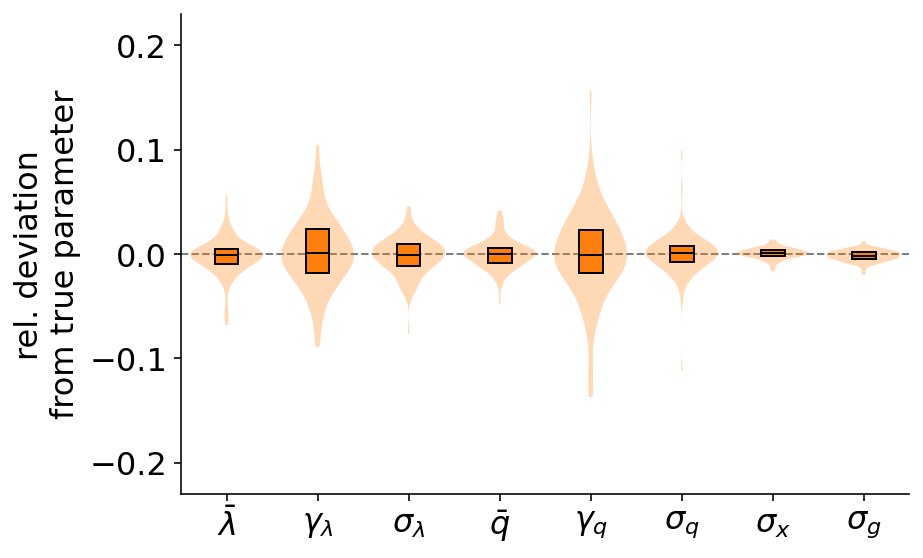

In [6]:
def plot_parameter_deviation_box(data_set_dirs, 
                                 include=None,
                                 drop=[],
                                 title=None,
                                 all_parameter_names=None, 
                                 err_bar_index=0, 
                                 ylim=[None, None],
                                 plot_file=None):

    parameter_names = copy.deepcopy(all_parameter_names)
            
    if include!=None:
        parameter_names = {}
        for i in include:
            parameter_names[i] = all_parameter_names[i]
    
    fig = plt.figure(figsize=(HALF_SIZE,FULL_HEIGHT))
    ax = fig.add_subplot()
    if title!=None:
        ax.set_title(title)
    for a in [ax]:
        a.spines["top"].set_visible(False)
        a.spines["right"].set_visible(False)
        a.spines['right'].set_color('none')
        a.spines['top'].set_color('none')


    inf_coll = []

    for i, data_set_dir in enumerate(data_set_dirs):
        inferred = read_header(find_files_in_outs(data_set_dir)[0], epsilon_err=0.005)
        inferred = exent_parameter_settings(inferred)

        true = read_parameter_file(get_ref(data_set_dir))
        true = exent_parameter_settings(true)

        inf_coll.append([(inferred[p][1]-true[p][1])/true[p][1] for p in parameter_names.keys()])            

    c_inf="tab:orange"
    c_init="tab:blue"
    alpha_inf=0.3

    inf_coll = np.array(inf_coll)
    for infer in np.transpose(inf_coll):
        quantiles = np.quantile(infer, np.array([0.00, 0.25, 0.50, 0.75, 1.00]))

    ax.axhline(0,lw=1, ls="--", color="tab:grey", zorder=-1)
    labels=list(parameter_names.keys())
    # bp = ax.boxplot(inf_coll, patch_artist = True,notch ='True',whis=0)
    
    parts = ax.violinplot(inf_coll,
                           showmeans=False, 
                           showmedians=False,
                           showextrema=False, 
                           widths=0.8)
    
    for pc in parts['bodies']:
        pc.set_facecolor("tab:orange")
        pc.set_alpha(0.3)

    boxplot_style = {'whiskerprops': {'linewidth': 0, 'color': 'None'},
                    'medianprops': {'linewidth': 1, 'color': 'black'},
                    'capprops': {'linewidth': 1, 'color': 'None'}}

    bplot = ax.boxplot(inf_coll, **boxplot_style, patch_artist=True, widths=0.26, whis=(0, 100))     
    for patch in bplot['boxes']:
        patch.set_facecolor("tab:orange")
            
    # axins = ax.inset_axes([0.7, 0.7, 0.3, 0.3])
    # axins.boxplot(inf_coll, **boxplot_style, patch_artist=True, widths=0.26, whis=(0, 100))
    # axins.set_ylim([-0.05,0.05])
    
    for i, infer in enumerate(np.transpose(inf_coll)):
        quantiles = np.quantile(infer, np.array([0.00, 0.25, 0.50, 0.75, 1.00]))
        # quantiles = np.quantile(infer, np.array([0.25, 0.75]))
        # axins.scatter(i, np.max(np.abs(quantiles)))
        # print(np.max(np.abs(quantiles))*100)
        
    ax.set_xticks(np.arange(len(labels))+1)
    ax.set_xticklabels([parameter_names[l] for l in labels])
    ax.set_ylabel("rel. deviation\nfrom true parameter")

    ax.set_ylim(ylim)
    plt.tight_layout()
    if plot_file!=None:
        plt.savefig(plot_file,bbox_inches='tight')
    plt.show()

plot_parameter_deviation_box(data_set_dirs, 
                             ["mean_lambda", "gamma_lambda", "sigma_lambda",
                              "mean_q", "gamma_q", "sigma_q", "sigma_x", "sigma_g"], 
                             all_parameter_names=parameter_names_unit_free, ylim=[-0.23,0.23],
                             plot_file=os.path.join("../../figures_for_method_paper/plots_main/synthetic_data/", "parameters.pdf"))


/Users/bjoern/mother_machine/RealTrace_figure_notebooks/nb_figures_for_ggp_paper/../../RealTrace_paper_analysis/plotting_src/read_utils.py:244: RuntimeWarning: invalid value encountered in sqrt
  param_error = np.sqrt(np.array(line.strip().split(',')[1:]).astype(float))


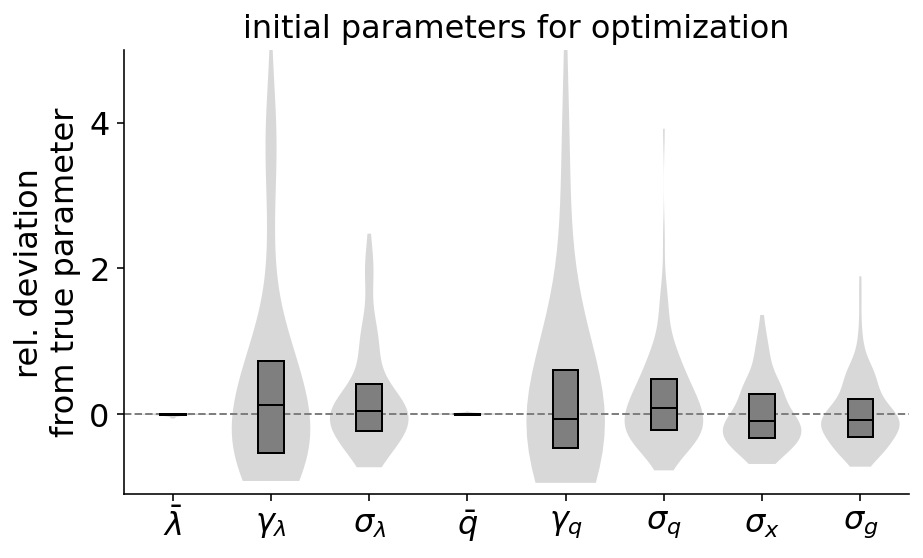

/Users/bjoern/mother_machine/RealTrace_figure_notebooks/nb_figures_for_ggp_paper/../../RealTrace_paper_analysis/plotting_src/read_utils.py:244: RuntimeWarning: invalid value encountered in sqrt
  param_error = np.sqrt(np.array(line.strip().split(',')[1:]).astype(float))


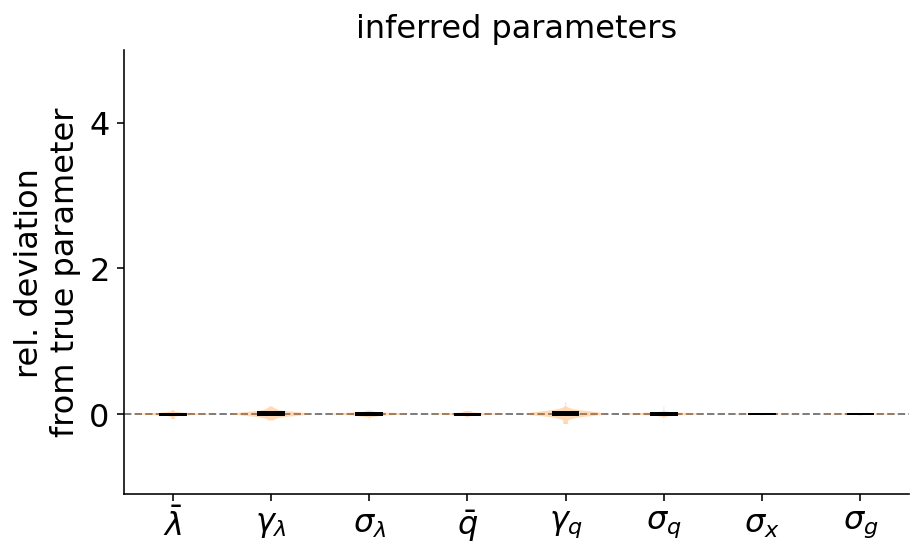

In [7]:
def plot_parameter_deviation_box_init(data_set_dirs, 
                                    include=None, drop=[],
                                    title=None,
                                    all_parameter_names=None, 
                                    err_bar_index=0, ylim=[None, None],
                                    plot_file=None):

    parameter_names = copy.deepcopy(all_parameter_names)
            
    if include!=None:
        parameter_names = {}
        for i in include:
            parameter_names[i] = all_parameter_names[i]
    
    fig = plt.figure(figsize=(HALF_SIZE,FULL_HEIGHT))
    ax = fig.add_subplot()
    if title!=None:
        ax.set_title(title)
    for a in [ax]:
        a.spines["top"].set_visible(False)
        a.spines["right"].set_visible(False)
        a.spines['right'].set_color('none')
        a.spines['top'].set_color('none')


    init_coll = []

    for i, data_set_dir in enumerate(data_set_dirs):
        init = read_header(find_files_in_outs(data_set_dir)[0], epsilon_err=0.005, read_state="init")

        init = exent_parameter_settings(init)

        true = read_parameter_file(get_ref(data_set_dir))
        true = exent_parameter_settings(true)

        init_coll.append([(init[p][1]-true[p][1])/true[p][1] for p in parameter_names.keys()])            

    c_inf="tab:orange"
    c_init="tab:blue"
    alpha_inf=0.3

    init_coll = np.array(init_coll)
    for infer in np.transpose(init_coll):
        quantiles = np.quantile(infer, np.array([0.00, 0.25, 0.50, 0.75, 1.00]))

    ax.axhline(0,lw=1, ls="--", color="tab:grey", zorder=-1)
    labels=list(parameter_names.keys())
    
    parts = ax.violinplot(init_coll,
                           showmeans=False, 
                           showmedians=False,
                           showextrema=False, 
                           widths=0.8)
    
    for pc in parts['bodies']:
        pc.set_facecolor("tab:grey")
        pc.set_alpha(0.3)

    boxplot_style = {'whiskerprops': {'linewidth': 0, 'color': 'None'},
                    'medianprops': {'linewidth': 1, 'color': 'black'},
                    'capprops': {'linewidth': 1, 'color': 'None'}}

    bplot = ax.boxplot(init_coll, **boxplot_style, patch_artist=True, widths=0.26, whis=(0, 100))     
    for patch in bplot['boxes']:
        patch.set_facecolor("tab:grey")

                
    ax.set_xticks(np.arange(len(labels))+1)
    ax.set_xticklabels([parameter_names[l] for l in labels])
    ax.set_ylabel("rel. deviation\nfrom true parameter")

    ax.set_ylim(ylim)
    plt.tight_layout()
    if plot_file!=None:
        plt.savefig(plot_file,bbox_inches='tight')
    plt.show()

plot_parameter_deviation_box_init(data_set_dirs, 
                             ["mean_lambda", "gamma_lambda", "sigma_lambda",
                              "mean_q", "gamma_q", "sigma_q", "sigma_x", "sigma_g"], 
                                  title="initial parameters for optimization",
                             all_parameter_names=parameter_names_unit_free, ylim=[-1.1, 5],
                             plot_file=os.path.join("../../figures_for_method_paper/supp/supp_parameters/", "parameters_init.pdf"))

plot_parameter_deviation_box(data_set_dirs, 
                             ["mean_lambda", "gamma_lambda", "sigma_lambda",
                              "mean_q", "gamma_q", "sigma_q", "sigma_x", "sigma_g"], 
                             title="inferred parameters",
                             all_parameter_names=parameter_names_unit_free, ylim=[-1.1, 5],
                             plot_file=os.path.join("../../figures_for_method_paper/supp/supp_parameters/", "parameters_inf.pdf"))


/Users/bjoern/mother_machine/RealTrace_figure_notebooks/nb_figures_for_ggp_paper/../../RealTrace_paper_analysis/plotting_src/read_utils.py:244: RuntimeWarning: invalid value encountered in sqrt
  param_error = np.sqrt(np.array(line.strip().split(',')[1:]).astype(float))


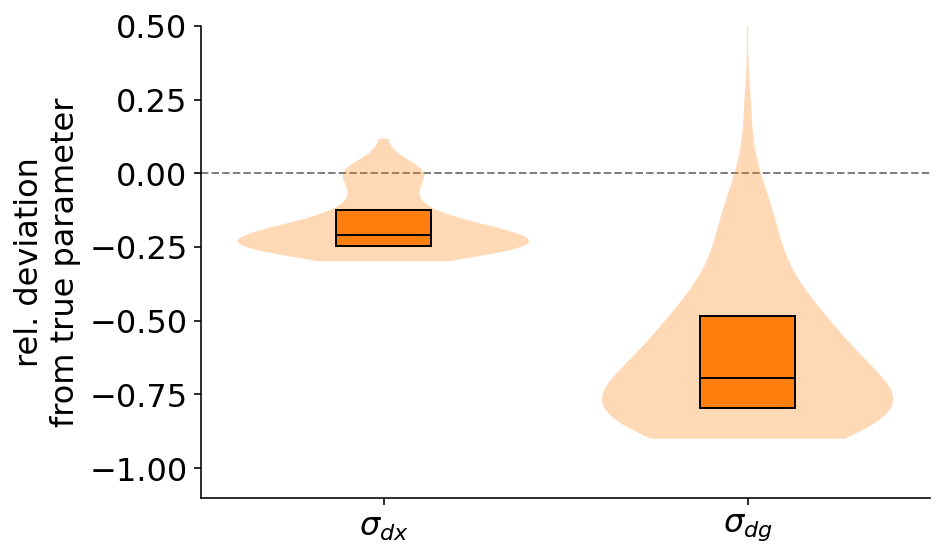

In [8]:


plot_parameter_deviation_box(data_set_dirs, 
                             [ "sigma_dx", "sigma_dg"], 
                             all_parameter_names=parameter_names_unit_free,ylim=[-1.1,0.5],
                             plot_file=os.path.join("../../figures_for_method_paper/supp/", "dx_dg_parameters.pdf"))

# plot_parameter_deviation_box_init(data_set_dirs, 
#                              [ "sigma_dx", "sigma_dg"], 
#                              all_parameter_names=parameter_names_unit_free,ylim=[-1.1,0.5],
#                              plot_file=os.path.join("../../figures_for_method_paper/supp/", "dx_dg_parameters.pdf"))


In [9]:
# def plot_true_vs_inferred(data_set_dirs, 
#                         parameter_name,
#                         title=None,
#                         all_parameter_names=None, 
#                         err_bar_index=0, ylim=[None, None],
#                         plot_file=None):

    
#     fig = plt.figure(figsize=(HALF_SIZE,FULL_HEIGHT))
#     ax = fig.add_subplot()
#     if title!=None:
#         ax.set_title(title)
#     for a in [ax]:
#         a.spines["top"].set_visible(False)
#         a.spines["right"].set_visible(False)
#         a.spines['right'].set_color('none')
#         a.spines['top'].set_color('none')


#     init_coll = []

#     for i, data_set_dir in enumerate(data_set_dirs):
#         inferred = read_header(find_files_in_outs(data_set_dir)[0], epsilon_err=0.005)
#         inferred = exent_parameter_settings(inferred)

#         true = read_parameter_file(get_ref(data_set_dir))
#         true = exent_parameter_settings(true)

#         inferred[parameter_name][1]
#         true[parameter_name][1]
        
#         c = 1/true["mean_q"][1]/true["mean_lambda"][1]*10
        
#         ax.scatter(true[parameter_name][1], inferred[parameter_name][1], s=c, color="tab:orange", alpha=0.5)
        
        
        
#     ax.axline( (0,0), slope=1, color="tab:grey", ls='--' )
#     ax.set_xlabel("true "+parameter_names_unit_free[parameter_name])
#     ax.set_ylabel("inferred "+parameter_names_unit_free[parameter_name])
    
#     plt.tight_layout()
#     if plot_file!=None:
#         plt.savefig(plot_file,bbox_inches='tight')
#     plt.show()

# plot_true_vs_inferred(data_set_dirs, "sigma_dx",
#                              all_parameter_names=parameter_names_unit_free, ylim=[-0.6, 2],)
#                              # plot_file=os.path.join("../../figures_for_method_paper/supp/supp_parameters/", "parameters_init.pdf"))

# plot_true_vs_inferred(data_set_dirs, "sigma_dg",
#                              all_parameter_names=parameter_names_unit_free, ylim=[-0.6, 2],)
#                              # plot_file=os.path.join("../../figures_for_method_paper/supp/supp_parameters/", "parameters_init.pdf"))


## Prediction of 100 simulated data sets

In [10]:
data_set_dir = os.path.join(base_dir,  data_set_name)
prediction_file_coll = []
simulation_file_coll = []
for ds in [data_set_dir.format(i,i) for i in range(100)]:
    if not os.path.exists(ds):
        continue
    if len(find_files_in_outs(ds, "prediction.csv"))>0:
        simulation_file_coll.append(find_files(ds, ".csv")[0])
        prediction_file_coll.append(find_files_in_outs(ds, "prediction.csv")[0])
    else:
        print(ds)
        pass


In [11]:
def get_dev_stats(simulation_file_coll, prediction_file_coll):
    rel_err = []
    z_stat_mean = [] 
    z_stat_std = []
    
    for i, _ in enumerate(prediction_file_coll[:]):
        
        indata = pd.read_csv(simulation_file_coll[i], dtype={"parent_id":str, "cell_id":str})
        
        prediction = pd.read_csv(prediction_file_coll[i], skiprows=header_lines(prediction_file_coll[i]), 
                                 dtype={"parent_id":str, "cell_id":str})

        cells_true = df2cells(indata, time="time_min", log_length="log_length", gfp="gfp", 
                                    cell_id="cell_id", parent_id="parent_id", 
                                    lt="lt", qt="qt")

        cells_prediction = ggp_df2cells(prediction, time="time", log_length="mean_x", gfp="mean_g", 
                                    cell_id="cell_id", parent_id="parent_id", 
                                    lt="mean_l", qt="mean_q")
        
        true_qs = np.concatenate([cell.qt for cell in cells_true])
        pred_qs = np.concatenate([cell.qt for cell in cells_prediction])
        cov_qqs = np.concatenate([cell.cov_qq for cell in cells_prediction])
        
        sq_err = np.mean((true_qs-pred_qs)**2)
        rel_err.append(np.sqrt(sq_err)/np.mean(true_qs))
        
        z_stat = (pred_qs-true_qs)/np.sqrt(cov_qqs)
        
        z_stat_mean.append(np.mean(z_stat))
        z_stat_std.append(np.std(z_stat))
        print(i, end=" ")
    return rel_err, z_stat_mean, z_stat_std
    
rel_err, z_stat_mean, z_stat_std = get_dev_stats(simulation_file_coll, prediction_file_coll)

0 1 2 3 4 5 6 7 8 9 10 11 12 13 14 15 16 17 18 19 20 21 22 23 24 25 26 27 28 29 30 31 32 33 34 35 36 37 38 39 40 41 42 43 44 45 46 47 48 49 50 51 52 53 54 55 56 57 58 59 60 61 62 63 64 65 66 67 68 69 70 71 72 73 74 75 76 77 78 79 80 81 82 83 84 85 86 87 88 89 90 91 92 93 94 95 96 97 98 99 

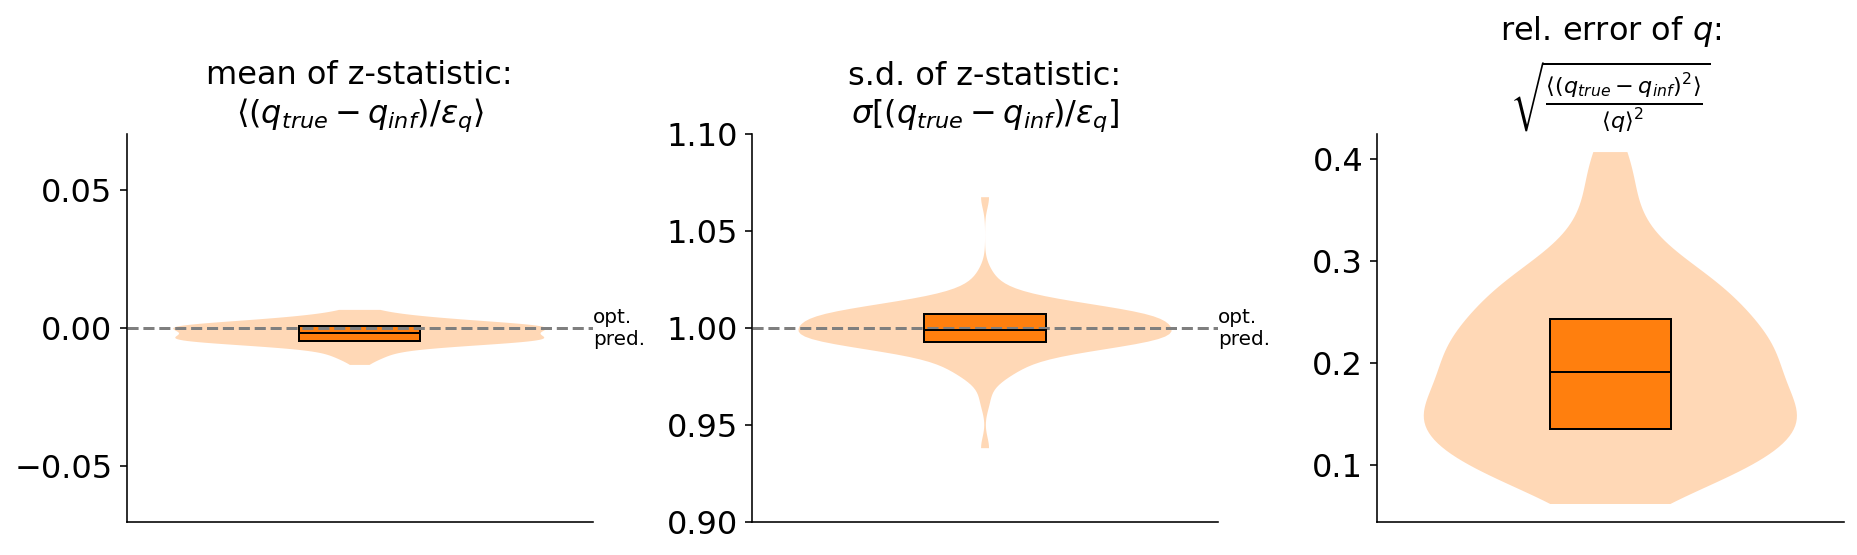

In [12]:

        
def plot_all_simulations_prediciton(rel_err, z_stat_mean, z_stat_std, plot_file=None):
    
    fig, ax = plt.subplots(1, 3, figsize=(FULL_SIZE, FULL_HEIGHT))
    ax = ax.ravel()
    for a in ax:
        a.spines["top"].set_visible(False)
        a.spines["right"].set_visible(False)
        a.spines['right'].set_color('none')
        a.spines['top'].set_color('none')

        
    #### MEAN #####
    ax[0].set_ylim([-0.07, 0.07])
    ax[0].set_xticklabels([])
    ax[0].set_title("mean of z-statistic:\n" +r"$\langle(q_{true}-q_{inf})/\epsilon_q\rangle$")
        
    parts = ax[0].violinplot([z_stat_mean],
                           showmeans=False, 
                           showmedians=False,
                           showextrema=False, 
                           widths=0.8)

    for pc in parts['bodies']:
        pc.set_facecolor("tab:orange")
        pc.set_alpha(0.3)

    boxplot_style = {'whiskerprops': {'linewidth': 0, 'color': 'None'},
                    'medianprops': {'linewidth': 1, 'color': 'black'},
                    'capprops': {'linewidth': 1, 'color': 'None'}}

    bplot = ax[0].boxplot([z_stat_mean], **boxplot_style, patch_artist=True, widths=0.26, whis=(0, 100))   
    for patch in bplot['boxes']:
        patch.set_facecolor("tab:orange")
    ax[0].set_xticks([])
    ax[0].yaxis.set_major_locator(matplotlib.ticker.MultipleLocator(base=0.05))
    ax[0].axhline(0, ls="--", color="tab:grey")
    ax[0].text(ax[0].get_xlim()[1], 0, "opt.\npred.", ha="left", va="center")
    
    #### STD #####
    ax[1].set_ylim([0.9, 1.1])    
    ax[1].set_title("s.d. of z-statistic:\n" +"$\sigma[(q_{true}-q_{inf})/\epsilon_q]$")
    
    
    parts = ax[1].violinplot([z_stat_std],
                           showmeans=False, 
                           showmedians=False,
                           showextrema=False, 
                           widths=0.8)

    for pc in parts['bodies']:
        pc.set_facecolor("tab:orange")
        pc.set_alpha(0.3)

    boxplot_style = {'whiskerprops': {'linewidth': 0, 'color': 'None'},
                    'medianprops': {'linewidth': 1, 'color': 'black'},
                    'capprops': {'linewidth': 1, 'color': 'None'}}

    bplot = ax[1].boxplot([z_stat_std], **boxplot_style, patch_artist=True, widths=0.26, whis=(0, 100))   
    for patch in bplot['boxes']:
        patch.set_facecolor("tab:orange")
    ax[1].set_xticks([])
    ax[1].yaxis.set_major_locator(matplotlib.ticker.MultipleLocator(base=0.05))
    ax[1].axhline(1, ls="--", color="tab:grey")
    ax[1].text(ax[1].get_xlim()[1], 1, "opt.\npred.", ha="left", va="center")

    
    #### REL_ERR #####
    ax[2].set_title("rel. error of $q$:\n" + r"$\sqrt{\frac{ \langle (q_{true}-q_{inf})^2\rangle }{\langle q\rangle^2}} $ ")
    
    
    parts = ax[2].violinplot([rel_err],
                           showmeans=False, 
                           showmedians=False,
                           showextrema=False, 
                           widths=0.8)

    for pc in parts['bodies']:
        pc.set_facecolor("tab:orange")
        pc.set_alpha(0.3)

    boxplot_style = {'whiskerprops': {'linewidth': 0, 'color': 'None'},
                    'medianprops': {'linewidth': 1, 'color': 'black'},
                    'capprops': {'linewidth': 1, 'color': 'None'}}

    bplot = ax[2].boxplot([rel_err], **boxplot_style, patch_artist=True, widths=0.26, whis=(0, 100))   
    for patch in bplot['boxes']:
        patch.set_facecolor("tab:orange")
    ax[2].set_xticks([])
    # ax[2].yaxis.set_major_locator(matplotlib.ticker.MultipleLocator(base=0.1))


    
    plt.tight_layout()
    if plot_file!=None:
        plt.savefig(plot_file, bbox_inches='tight')
    plt.show()
    

plot_all_simulations_prediciton(rel_err, z_stat_mean, z_stat_std,
                                plot_file=os.path.join("../../figures_for_method_paper/supp/supp_parameters/", "random_parameter_sims_posteriors.pdf"))


/Users/bjoern/mother_machine/RealTrace_figure_notebooks/nb_figures_for_ggp_paper/../../RealTrace_paper_analysis/plotting_src/read_utils.py:244: RuntimeWarning: invalid value encountered in sqrt
  param_error = np.sqrt(np.array(line.strip().split(',')[1:]).astype(float))


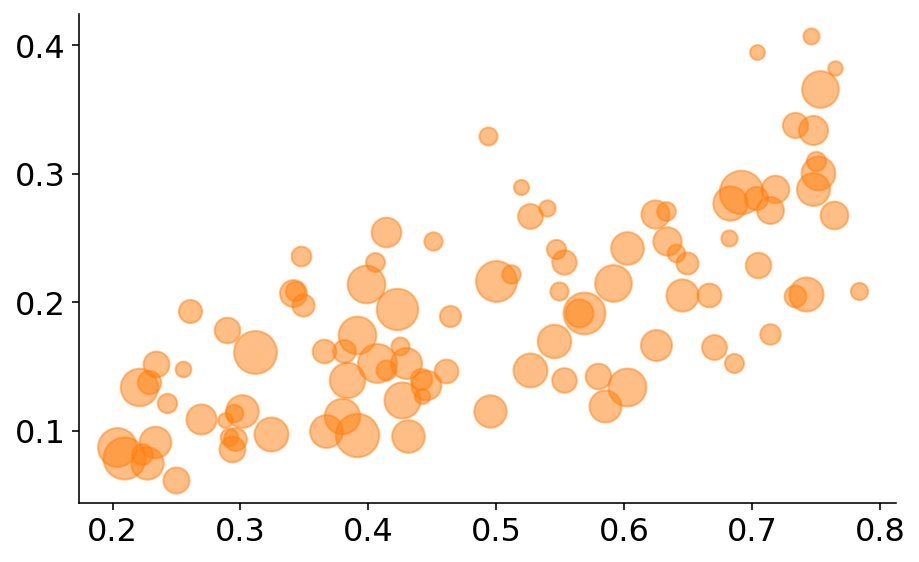

In [13]:
def plot_rel_err_vs_noise(data_set_dirs, 
                        rel_err,
                        title=None,
                        all_parameter_names=None, 
                        err_bar_index=0,
                        plot_file=None):

    
    fig = plt.figure(figsize=(HALF_SIZE,FULL_HEIGHT))
    ax = fig.add_subplot()
    if title!=None:
        ax.set_title(title)
    for a in [ax]:
        a.spines["top"].set_visible(False)
        a.spines["right"].set_visible(False)
        a.spines['right'].set_color('none')
        a.spines['top'].set_color('none')

    init_coll = []

    for i, data_set_dir in enumerate(data_set_dirs):
        inferred = read_header(find_files_in_outs(data_set_dir)[0], epsilon_err=0.005)
        inferred = exent_parameter_settings(inferred)

        true = read_parameter_file(get_ref(data_set_dir))
        true = exent_parameter_settings(true)

        ax.scatter(np.sqrt(true["var_q"][1]/(2*true["gamma_q"][1]))/true["mean_q"][1], 
                   rel_err[i], 
                   s=true["mean_lambda"][1]*10000,
                   color="tab:orange", 
                   alpha=0.5)
    
    plt.tight_layout()
    if plot_file!=None:
        plt.savefig(plot_file,bbox_inches='tight')
    plt.show()

plot_rel_err_vs_noise(data_set_dirs, rel_err,
                             all_parameter_names=parameter_names_unit_free,)
                             # plot_file=os.path.join("../../figures_for_method_paper/supp/supp_parameters/", "parameters_init.pdf"))


## Predictions simulated data


In [14]:
# get files


directory =  '../../data_realtrace_paper/glucose_hi1_simulation1000_adder_wo_bleaching/glucose_hi1_simulation1000_adder_wo_bleaching_0/'

sample = directory.split("/")[-2]

paramter_settings = {'mean_lambda': 'free',
                    'gamma_lambda': 'free',
                    'var_lambda': 'free',
                    'mean_q': 'free',
                    'gamma_q': 'free',
                    'var_q':'free',
                    'beta':'fixed',
                    'var_x':'free',
                    'var_g':'free',
                    'var_dx':'free',
                    'var_dg':'free'} 


paramter_settings_list = [paramter_settings]
filebase = default_filebase(directory, sample) # default

dat_file = directory + sample + ".csv"
prediction_file_f, prediction_file_b, prediction_file = get_prediction_files(filebase, paramter_settings_list)
iter_file, final_file = get_minimization_file(filebase, paramter_settings)

indata = pd.read_csv(dat_file, dtype={"parent_id":str, "cell_id":str})
prediction = pd.read_csv(prediction_file, skiprows=header_lines(prediction_file), 
                         dtype={"parent_id":str, "cell_id":str})
# indata["cell_id"] = indata["lane"].astype(str) + '.' + indata["cell_id"].astype(str)
# indata["parent_id"] = indata["lane"].astype(str) + '.' + indata["parent_id"].astype(str)

cells_true = df2cells(indata, time="time_min", log_length="log_length", gfp="gfp", 
                            cell_id="cell_id", parent_id="parent_id", 
                            lt="lt", qt="qt")

cells_prediction = ggp_df2cells(prediction, time="time", log_length="mean_x", gfp="mean_g", 
                            cell_id="cell_id", parent_id="parent_id", 
                            lt="mean_l", qt="mean_q")

cells_noise = df2cells(indata, time="time_min", log_length="log_length_noise", gfp="gfp_noise", 
                            cell_id="cell_id", parent_id="parent_id", 
                            lt="lt", qt="qt")


full_data = pd.read_csv(directory + sample + "_full.csv", 
                       dtype={"parent_id":str, "cell_id":str})

cells_full = df2cells(full_data, time="time_min", log_length="log_length", gfp="gfp", 
                            cell_id="cell_id", parent_id="parent_id", 
                            lt="lt", qt="qt")



In [15]:

def get_path_idx(cells, idx0=0):
    idx = []
    last_cell = cells[idx0].parent_id
    for i, _ in enumerate(cells):
        if last_cell == cells[i].parent_id: 
            last_cell = cells[i].cell_id
            idx.append(i)
    return idx

def gaussian(x, y):
    mean = np.mean(y)
    sigma = np.std(y)
    return 1./(np.sqrt(2*np.pi)*sigma) * np.exp(-(x-mean)**2/(2*sigma**2))


def gauss_function(x, a, x0, sigma):
    return a*np.exp(-(x-x0)**2/(2*sigma**2))


The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


/var/folders/_h/4605456d743bfjqsq6r1jcdm0000gp/T/ipykernel_27482/4160671218.py:198: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


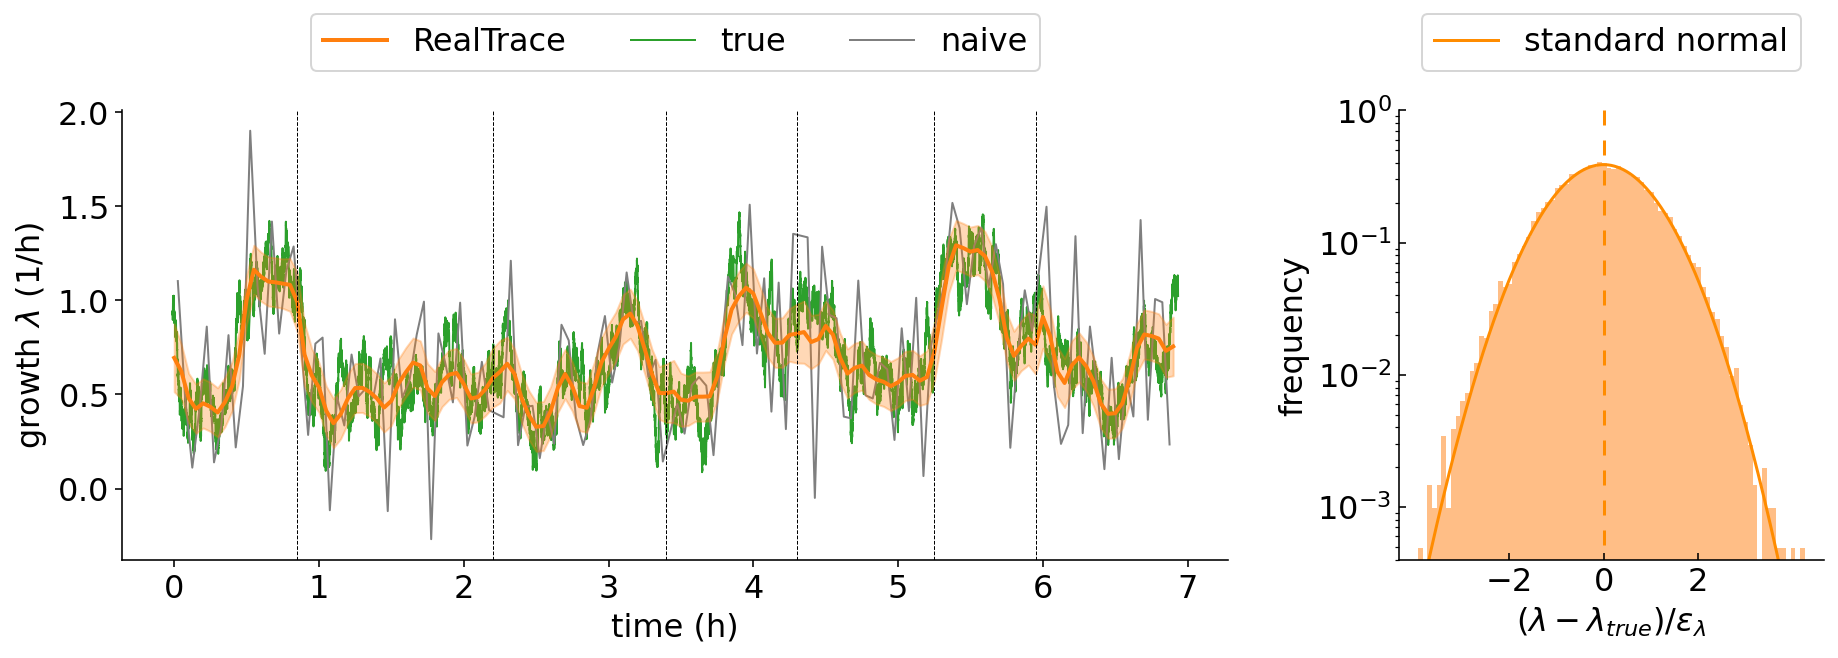

/var/folders/_h/4605456d743bfjqsq6r1jcdm0000gp/T/ipykernel_27482/4160671218.py:198: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


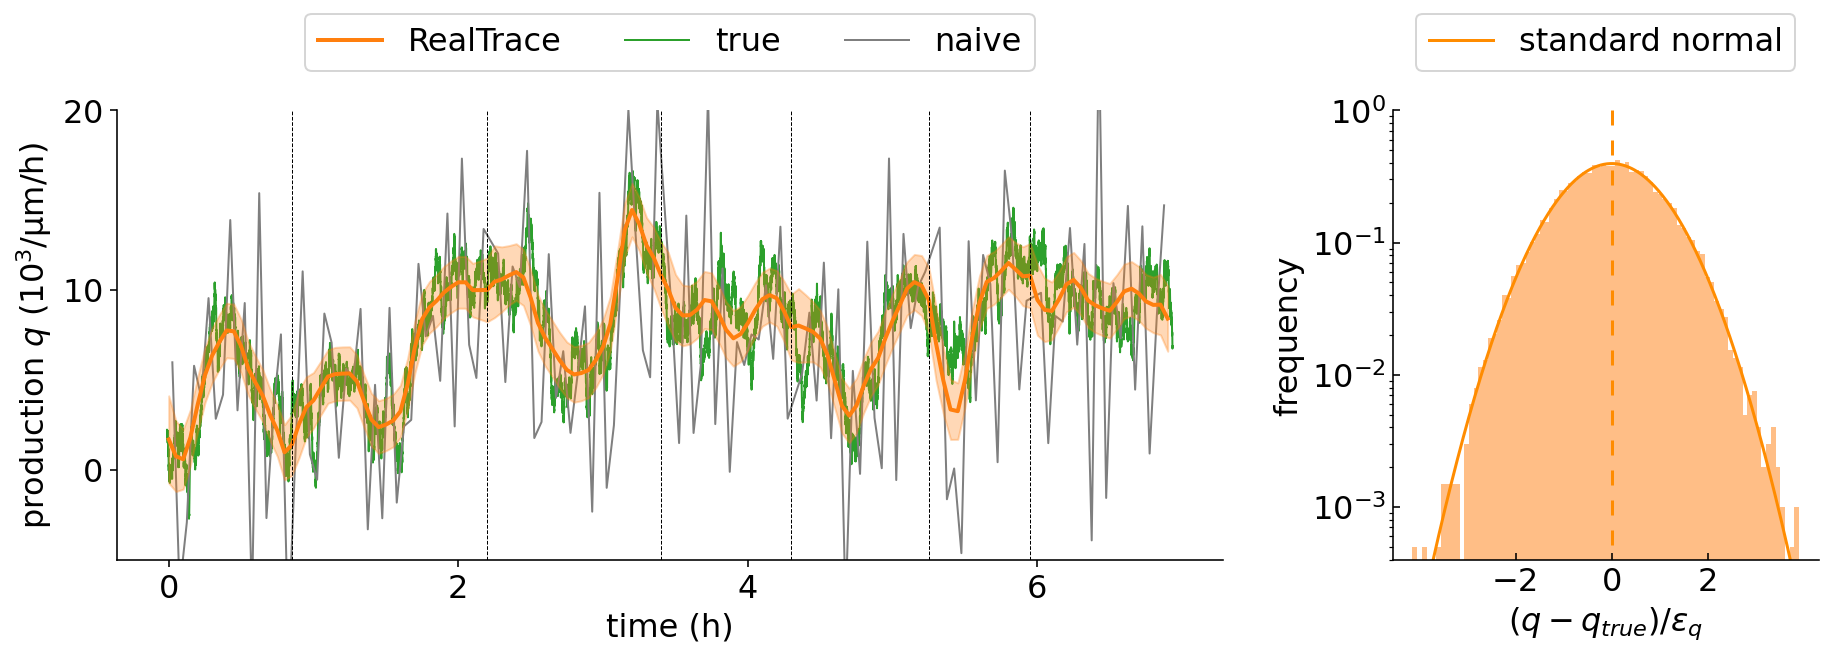

In [16]:
%load_ext autoreload
%autoreload 2



def plot_rate_residual(cells_true, cells_prediction, cells_noise, idx_cells, quantity, cells_full=None,  
                title="", xlim=[None, None], ylim=[None, None], plot_file=None, beta=0, fit_gaussian=True):
    # definitions for the axes

            
    
    left, width = 0.1, 0.65
    bottom, height = 0.1, 0.65
    spacing = 0.1

    hist_width = 0.25
    
    rect_scatter = [left, bottom, width, height]
    rect_histy = [left + width + spacing, bottom, hist_width, height]

    tot_width = rect_histy[0] + rect_histy[2]
    fig = plt.figure(figsize=(FULL_SIZE/tot_width, 1.2*FULL_HEIGHT))    
    
    ax = plt.axes(rect_scatter)

    ax_histy = plt.axes(rect_histy)
    ax_histy.tick_params(direction='in', labelleft=True)
    # ax_histy.set_title("distribution")
    
    # ax.set_title("cell lineage for synthetic data")    
    for a in [ax, ax_histy]:
        a.spines["top"].set_visible(False)
        a.spines["right"].set_visible(False)

        # turn off the right spine/ticks
        a.spines['right'].set_color('none')
        a.yaxis.tick_left()

        # turn off the top spine/ticks
        a.spines['top'].set_color('none')
        a.xaxis.tick_bottom()
        # remove first tick
        # a.xaxis.get_major_ticks()[0].set_visible(False)
        
    ax_histy.set_ylabel("frequency")
    if quantity == "lambda":
        ax_histy.set_xlabel(r"$(\lambda - \lambda_{true})/\varepsilon_\lambda$")
        
    elif quantity =="q":
        ax_histy.set_xlabel(r"$(q - q_{true})/\varepsilon_q$")


    ###
    ax.set_xlabel("time (h)")
    ax.set_ylabel(title)

    label_cd = "cell division"
    label_p = "RealTrace"
    label_t = "true"
    label_n = "naive"

    prediction_coll = []
    noise_coll = []
    err_coll = []
    time_prediction_coll = []
    true_coll = []
    time_true_coll = []

    
    for i, _ in enumerate(cells_noise):
        if quantity == "lambda":
            prediction = np.array(cells_prediction[i].lt)
            err = np.sqrt(cells_prediction[i].cov_ll)
            true = np.array(cells_true[i].lt)
            
        elif quantity =="q":
            prediction = np.array(cells_prediction[i].qt)/1e3
            err = np.sqrt(cells_prediction[i].cov_qq)/1e3
            true = np.array(cells_true[i].qt)/1e3
            
             
        # prediction
        time_true_coll.append(cells_prediction[i].time)
        time_prediction_coll.append(cells_prediction[i].time)
        prediction_coll.append(prediction)
        err_coll.append(err)
        
        # truth
        true_coll.append(true)
    
    time_full_coll = []
    full_coll = []
    
    if cells_full!=None:
        for i, _ in enumerate(cells_full):
            if quantity == "lambda":
                full = np.array(cells_full[i].lt)
            elif quantity =="q":
                full = np.array(cells_full[i].qt)/1e3   

            time_full_coll.append(cells_full[i].time)
            full_coll.append(full)
            
    # noise
    if quantity == "lambda":
        naive_cells = naive_rate_for_all_cells(cells_noise, 1, naive_growth_rate_skip_div)
    elif quantity =="q":
        naive_cells = naive_rate_for_all_cells(cells_noise, 1, naive_production_rate, beta)

    time_noise_coll = [cell.time_naive_rate for cell in naive_cells]
    
    if quantity == "lambda":
        noise_coll = [cn.naive_rate for cn in naive_cells]
    elif quantity =="q":
        noise_coll = [cn.naive_rate/1e3 for cn in naive_cells]

    
    # Plots
    traces_time = index_nested(time_prediction_coll, idx_cells, True)
    time_shift= traces_time[0]
    
    ax.plot( (traces_time - time_shift)/60., 
             (index_nested(prediction_coll, idx_cells, True))*60, 
             color='tab:orange',  label=label_p, alpha=1, zorder=2,lw=2)

    ax.fill_between( (traces_time-time_shift)/60., 
                     (deep_flatten(index_nested(prediction_coll, idx_cells, True))-deep_flatten(index_nested(err_coll, idx_cells, True)))*60, 
                     (deep_flatten(index_nested(prediction_coll, idx_cells, True))+deep_flatten(index_nested(err_coll, idx_cells, True)))*60, 
                       color="tab:orange", alpha=0.3, zorder=2)
    

    ax.plot( (index_nested(time_full_coll, idx_cells, True)-time_shift)/60., 
             index_nested(full_coll, idx_cells, True)*60., 
             color='tab:green',  label=label_t, alpha=1, lw=1, zorder=1)

    
    ax.plot( (index_nested(time_noise_coll, idx_cells, True)-time_shift)/60., 
             index_nested(noise_coll, idx_cells, True)*60., 
             color='tab:grey', lw=1, label=label_n, alpha=1, ls='-', zorder=1)

    
    # cell division
    for i in idx_cells[:-1]:
        ax.axvline( (cells_prediction[i].time[-1]-time_shift)/60.,color='black', ls='--', lw=0.5)
        label_cd = None

    if xlim!=[None,None]:
        ax.set_xlim(xlim)
    if ylim!=[None,None]:
        ax.set_ylim(ylim)
    ax.ticklabel_format(axis='y', style='scientific', scilimits=[-4,4], useMathText=True)

        
    ############################################
    ############################################
    # Hist
    ############################################
    ############################################
    ## true
    z_stat = (deep_flatten(prediction_coll)-deep_flatten(true_coll))/deep_flatten(err_coll)
    hist, bin_edges = np.histogram(z_stat, density=False, bins="auto")
    bin_centers = bin_edges[:-1] + np.diff(bin_edges)/2
    hist = np.array(hist)
    hist = hist/(np.sum(hist*np.diff(bin_edges)))
#         hist= hist/(np.sum(hist))


    popt, pcov = curve_fit(gauss_function, bin_centers, hist, p0=[np.max(z_stat),np.mean(z_stat), np.std(z_stat)])

    
    ax_histy.bar(bin_centers, hist, width=np.diff(bin_edges),
            edgecolor=None, align="center", color="tab:orange",
            alpha=0.5,) #label=r"$\mu={:.2f}$" "\n" r"$\sigma={:.2f}$".format(np.mean(z_stat), np.std(z_stat)))

    x_temp = np.linspace(np.min(z_stat) , np.max(z_stat), 1000)
    

    ax_histy.plot(x_temp, gauss_function(x_temp, popt[0], 0,1), color="darkorange", alpha=1, 
                  label="standard normal")
    ax_histy.axvline(0, color="darkorange", ls=(5, (5, 5)))
    

    ax_histy.set_xticks([-2,0,2])
    ax_histy.set_yscale('log')
    xlim_lower = gauss_function(popt[1]-3*popt[2], *popt) 
    xlim_upper = np.max(hist) * np.max(hist)/gauss_function(popt[1]-3*popt[2], *popt)/50

    ax_histy.set_ylim(4e-4,1)
    h, l = ax.get_legend_handles_labels()
    
    ax.legend(h, l, ncol=3, loc="upper center", bbox_to_anchor=(0.5,1.25))
    ax_histy.legend(loc="upper center", bbox_to_anchor=(0.5,1.25))
    
    if quantity =="q":
        ax.xaxis.set_major_locator(matplotlib.ticker.MultipleLocator(base=2))
        ax.yaxis.set_major_locator(matplotlib.ticker.MultipleLocator(base=10))

    plt.tight_layout()
    if plot_file!=None:
        plt.savefig(plot_file, bbox_inches='tight')
    plt.show()




plot_rate_residual(cells_true, cells_prediction, cells_noise, get_longest_path(cells_noise)[:7], 
                   "lambda",  
                   cells_full=cells_full,
                   title=r"growth $\lambda\ $(1/h)", 
                   xlim=[None, None], 
                   # ylim = [-0.003, 0.025],
                   fit_gaussian=False,
                   plot_file="../../figures_for_method_paper/supp/synthetic_data/lineage_lambda_sim_residual.pdf")


plot_rate_residual(cells_true, cells_prediction, cells_noise, get_longest_path(cells_noise)[:7], 
                   "q",  
                   cells_full=cells_full,
                   title=r"production $q$ ($\mathrm{10^3/\mu m/h}$)", 
                   xlim=[None, None], 
                   ylim = [-5, 20],
                   fit_gaussian=False,
                   plot_file="../../figures_for_method_paper/plots_main/synthetic_data/lineage_q_sim_residual.pdf")




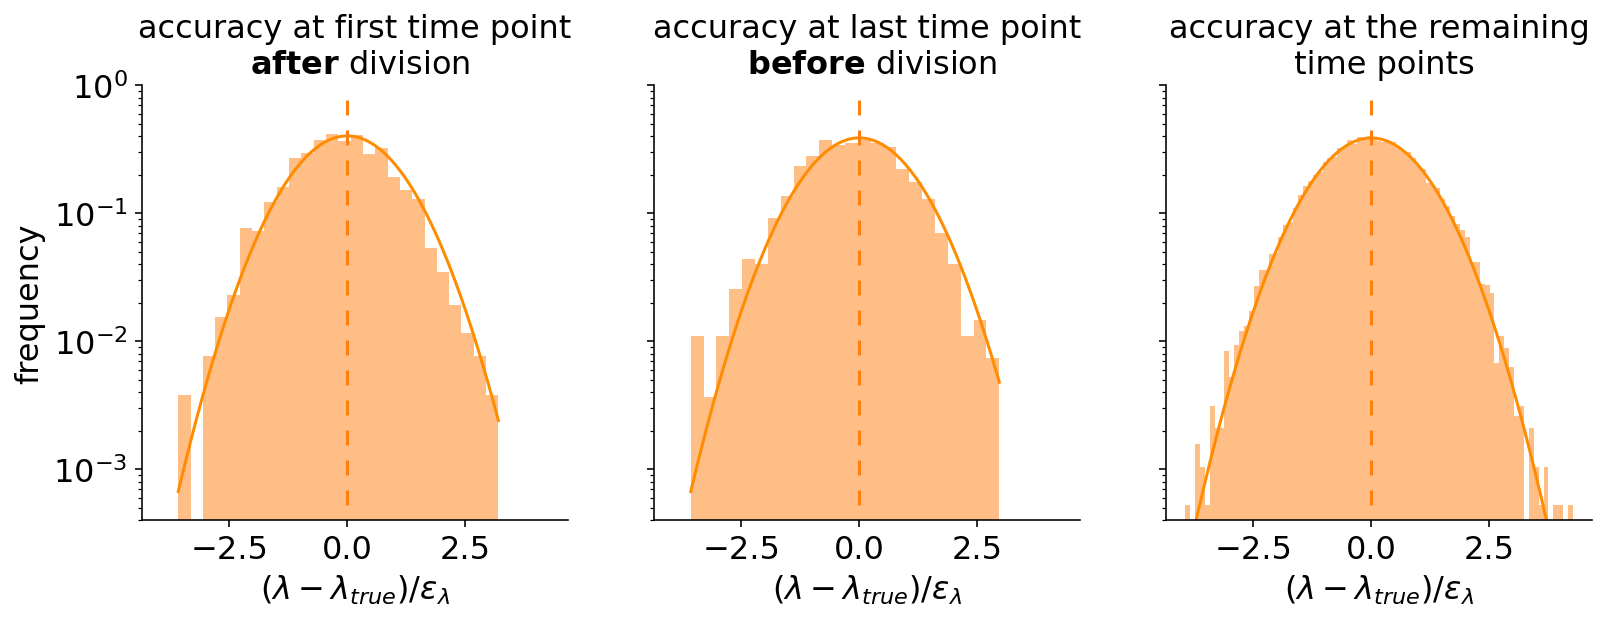

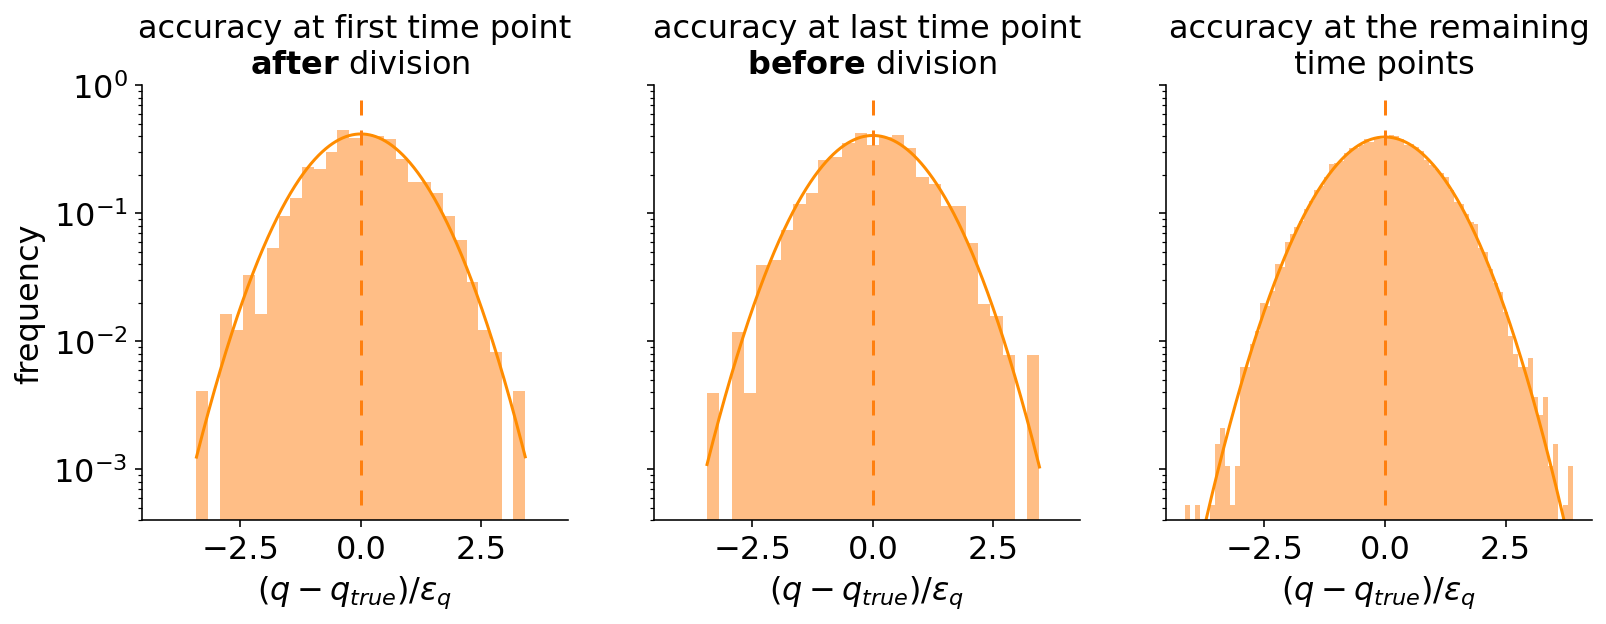

In [17]:
def plot_err_cell_cycle_ends(cells_true, cells_prediction, cells_noise, quantity, cells_full=None,  
                title="", xlim=[None, None], ylim=[None, None], plot_file=None, beta=0, fit_gaussian=True):
    
    fig, ax = plt.subplots(1,3, figsize=(FULL_SIZE, FULL_HEIGHT), sharex=True, sharey=True)
    
   
    ax[0].set_ylabel("frequency")
        
    for a in ax:
        a.spines["top"].set_visible(False)
        a.spines["right"].set_visible(False)

        # turn off the right spine/ticks
        a.spines['right'].set_color('none')
        a.yaxis.tick_left()

        # turn off the top spine/ticks
        a.spines['top'].set_color('none')
        a.xaxis.tick_bottom()
        # remove first tick
        # a.xaxis.get_major_ticks()[0].set_visible(False)
        if quantity == "lambda":
            a.set_xlabel(r"$(\lambda - \lambda_{true})/\varepsilon_\lambda$")

        elif quantity =="q":
            a.set_xlabel(r"$(q - q_{true})/\varepsilon_q$")
        a.set_yscale('log')
        a.set_ylim(4e-4,1)

        
        mid_err = []
        beg_err = []
        end_err = []
        
    for i, _ in enumerate(cells_true):
        if quantity == "lambda":
            prediction = np.array(cells_prediction[i].lt)
            err = np.sqrt(cells_prediction[i].cov_ll)
            true = np.array(cells_true[i].lt)

        elif quantity =="q":
            prediction = np.array(cells_prediction[i].qt)
            err = np.sqrt(cells_prediction[i].cov_qq)
            true = np.array(cells_true[i].qt)

        # mid_err = np.append(mid_err, (prediction[1:-1]-true[1:-1])/err[1:-1])
        # beg_err = np.append(beg_err, (prediction[:1]-true[:1])/err[:1])
        # end_err = np.append(end_err, (prediction[-1:]-true[-1:])/err[-1:])
        
        
        mid_err = np.append(mid_err, (prediction[1:-1]-true[1:-1])/err[1:-1])
        beg_err = np.append(beg_err, (prediction[:1]-true[:1])/err[:1])
        end_err = np.append(end_err, (prediction[-1:]-true[-1:])/err[-1:])


    for i, err in enumerate([beg_err, end_err, mid_err]):
        z_stat = deep_flatten(err)
        hist, bin_edges = np.histogram(z_stat, density=False, bins="auto")
        bin_centers = bin_edges[:-1] + np.diff(bin_edges)/2
        hist = np.array(hist)
        hist = hist/(np.sum(hist*np.diff(bin_edges)))

        popt, pcov = curve_fit(gauss_function, bin_centers, hist, p0=[np.max(z_stat),np.mean(z_stat), np.std(z_stat)])

        ax[i].bar(bin_centers, hist, width=np.diff(bin_edges),
                edgecolor=None, align="center", color="tab:orange",
                alpha=0.5, label=r"$\mu={:.2f}$" "\n" r"$\sigma={:.2f}$".format(np.mean(z_stat), np.std(z_stat)))

        
        x_temp = np.linspace(np.min(z_stat) , np.max(z_stat), 1000)
        # ax[i].plot(x_temp, gauss_function(x_temp, popt[0], np.mean(z_stat), np.std(z_stat)), color="darkorange", alpha=1)
        ax[i].plot(x_temp, gauss_function(x_temp, popt[0], 0, 1), color="darkorange", alpha=1)
        
        ax[i].axvline(0, color="tab:orange", ls=(5, (5, 5)))

        # ax[i].legend( loc="center", bbox_to_anchor=(0.5,1.1))
    
    ax[0].set_title("accuracy at first time point\n $\\mathbf{after}$ division", y=1.)
    ax[1].set_title("accuracy at last time point\n $\\mathbf{before}$ division", y=1.)
    ax[2].set_title("accuracy at the remaining\n time points", y=1.)
    if plot_file!=None:
        plt.savefig(plot_file, bbox_inches='tight')
    plt.show()
    
plot_err_cell_cycle_ends(cells_true, cells_prediction, cells_noise, 
                   "lambda",  
                   cells_full=cells_full,
                   xlim=[None, None], 
                   ylim = [-100, 400],
                   fit_gaussian=False,
                    plot_file="../../figures_for_method_paper/supp/synthetic_data/cell_cycle_edges_lineage_l_sim_residual.pdf")

plot_err_cell_cycle_ends(cells_true, cells_prediction, cells_noise, 
                   "q",  
                   cells_full=cells_full,
                   title=r"GFP production rate $q$ (1/$\mu$m/min)", 
                   xlim=[None, None], 
                   ylim = [-100, 400],
                   fit_gaussian=False,
                    plot_file="../../figures_for_method_paper/supp/synthetic_data/cell_cycle_edges_lineage_q_sim_residual.pdf")

### Comparison with naive

In [32]:

def compare_sliding_mean_to_prediction(cells_true, cells_prediction, cells_noise, quantity,  
                                       title="", 
                                       xlim=[None, None], ylim=[None, None], 
                                       window_sizes=[1], 
                                       plot_file=None, 
                                       normy = None,
                                       log=False,
                                       beta=0, 
                                       dt=3, 
                                       mark_x = None):

    plt.figure(figsize=(HALF_SIZE, FULL_HEIGHT))
    ax = plt.axes()
    # ax.set_title("estimation error of GFP production rate over a time window", pad=10)
    
    for a in [ax]:
        a.spines["top"].set_visible(False)
        a.spines["right"].set_visible(False)
        # set the x-spine
        # a.spines['left'].set_position('zero')

        # turn off the right spine/ticks
        a.spines['right'].set_color('none')
        a.yaxis.tick_left()
    
    ax.set_xlabel("number of averaged data points")
    ax.set_ylabel(title)

    cvs_naive = []
    cvs_prediction = []
    

    for i, window in enumerate(window_sizes):
        if quantity == "lambda":
            if window>1:
                naive_cells = naive_rate_for_all_cells(cells_noise, window-1, naive_growth_rate_skip_div)
            sliding_true_cells = sliding_rate_for_all_cells(cells_true, window, sliding_growth_rate)
            sliding_prediction_cells = sliding_rate_for_all_cells(cells_prediction, window, sliding_growth_rate)

        elif quantity =="q":
            if window>1:
                naive_cells = naive_rate_for_all_cells(cells_noise, window-1, naive_production_rate_skip_div, beta)
            sliding_true_cells = sliding_rate_for_all_cells(cells_true, window, sliding_production_rate)
            sliding_prediction_cells = sliding_rate_for_all_cells(cells_prediction, window, sliding_production_rate)

        
        true_window = deep_flatten([ct.sliding_rate for  ct in  sliding_true_cells])
        
        print(window, end=' ')
        if window>1:
            naive_window = deep_flatten([ct.naive_rate for  ct in  naive_cells])
            cvs_naive.append([window, np.sqrt(np.mean(np.array(true_window-naive_window)**2))/normy])
        
        prediction_window = deep_flatten([ct.sliding_rate for  ct in  sliding_prediction_cells])
        cvs_prediction.append([window, np.sqrt(np.mean((true_window-prediction_window)**2))/normy])
        
    
    ax.plot(np.transpose(cvs_prediction)[0],np.transpose(cvs_prediction)[1],'o', color="tab:orange", label="RealTrace")
    ax.plot(np.transpose(cvs_naive)[0], np.transpose(cvs_naive)[1], 'o', color="tab:grey", label="naive")
    # ax.axhline(np.transpose(cvs_prediction)[1][0], color="tab:orange", ls='--')

    print(np.transpose(cvs_prediction)[0],np.transpose(cvs_prediction)[1])
    print(np.transpose(cvs_naive)[0], np.transpose(cvs_naive)[1])
    x0 = np.transpose(cvs_prediction)[0][0]
    x1 = np.transpose(cvs_naive)[0][np.argwhere(np.transpose(cvs_naive)[1]<=np.transpose(cvs_prediction)[1][0])[0]][0]
    y0 = np.transpose(cvs_prediction)[1][0]
    y1 = np.transpose(cvs_prediction)[1][0]
    # print([x0, x1], 
    #         [y0, y1])
    ax.plot([x0, x1], 
            [y0, y1], 
            color="tab:orange", ls='--')
 

    if ylim!=[None, None]:
        ax.set_ylim(ylim)    
        
    if log:
        ax.set_yscale('log')
        ax.set_xscale('log')

        ticks = np.ravel([np.array([1, 5])*(10.**i) for i in np.arange(-10,10)])

        ylim = ax.get_ylim()
        yticks = ticks[(ticks>ylim[0]) * (ticks<=ylim[1])]
        ax.set_yticks(yticks)
        ax.set_yticklabels(yticks)
        
        xlim = ax.get_xlim()
        ticks =np.array([1, 5, 10, 20])
        xticks = ticks[(ticks>xlim[0]) * (ticks<=xlim[1])]
        ax.set_xticks(xticks)
        ax.set_xticklabels(["{:d}".format(i) for i in xticks])

        def power_law(x, a, b):
            return a*x**(-b)

        popt, pcov = curve_fit(power_law, np.transpose(cvs_prediction)[0],
                                       np.transpose(cvs_prediction)[1])
        ax.plot(np.transpose(cvs_prediction)[0], 
                power_law(np.transpose(cvs_prediction)[0], *popt), 
                label=r"$\sim$ exp(-{:.2f})".format(popt[1]),
               ls="-", color="tab:orange")

    
    else:
        from matplotlib.ticker import MaxNLocator
        import matplotlib.ticker 
    
        ax.xaxis.set_major_locator(MaxNLocator(integer=True))
 
        ylim = ax.get_ylim()
        yticks = [0.05, 0.1, 0.5, 1]
        ax.set_ylim(ylim)

    print(np.transpose(cvs_naive)[1]/np.transpose(cvs_prediction)[1][1:])

#     # add top x axis
#     ax_top = ax.secondary_xaxis('top', functions=(lambda x:  x*dt, 
#                                                     lambda x: x/dt))
#     ax_top.set_xlabel(r'window time (min)')
    
    if mark_x!=None:
        mark_x /=dt
        ax.axvline(mark_x, color="grey", lw=1)
        ax.text(mark_x, np.max(np.transpose(cvs_naive)[1])*0.92, 
                "mean dbl\ntime", 
                color="black",
                backgroundcolor='w', 
                ha='center', fontsize=SMALL_SIZE)
        
    ax.legend(loc="upper center", bbox_to_anchor=(0.5,1), ncol=2)
    plt.tight_layout()
    if plot_file!=None:
        plt.savefig(plot_file, bbox_inches='tight')
    plt.show()



In [19]:
read_header(final_file)["beta"][1]

0.0

1 2 3 4 5 6 7 8 9 10 11 12 13 14 15 16 17 18 19 20 21 [ 1.  2.  3.  4.  5.  6.  7.  8.  9. 10. 11. 12. 13. 14. 15. 16. 17. 18.
 19. 20. 21.] [0.20531001 0.14898451 0.11950223 0.09625967 0.0837027  0.07169051
 0.06577101 0.05890781 0.0553466  0.05116746 0.04868758 0.04575598
 0.04389206 0.04175934 0.04023813 0.03860523 0.03729499 0.03591669
 0.03478952 0.03369067 0.03275134]
[ 2.  3.  4.  5.  6.  7.  8.  9. 10. 11. 12. 13. 14. 15. 16. 17. 18. 19.
 20. 21.] [0.49792692 0.36528634 0.25037181 0.22981553 0.18838996 0.17871862
 0.15710112 0.15163885 0.13775678 0.13395453 0.12469432 0.12150498
 0.11489476 0.11217496 0.1073655  0.10505113 0.1013583  0.09887786
 0.09591525 0.09346323]
[3.34213886 3.05673231 2.60100413 2.7456165  2.62782283 2.71728588
 2.666898   2.7398041  2.69227308 2.75130779 2.72520278 2.76826829
 2.75135469 2.78777755 2.78111274 2.81676225 2.82203869 2.84217351
 2.84693831 2.853722  ]


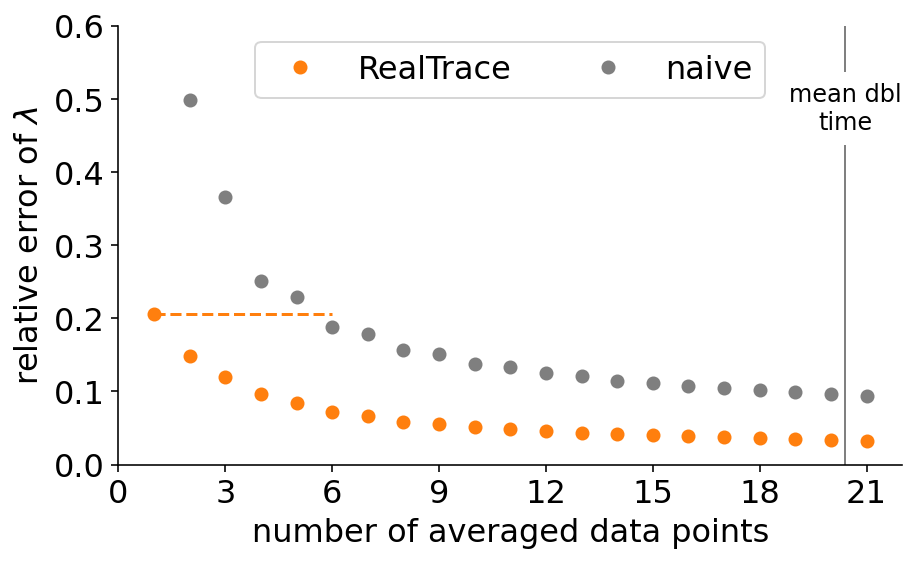

In [20]:
compare_sliding_mean_to_prediction(cells_true, cells_prediction, cells_noise,  
                                   "lambda",  
                                    # title=r"relative error of $\lambda$ $\frac{\sqrt{\langle(\lambda - \lambda_{true})^2\rangle}}{\bar \lambda} $", 
                                    # title=r"relative error of $\lambda$ $\frac{\sqrt{\langle(\lambda - \lambda_{true})^2\rangle}}{\bar \lambda} $", 
                                    title=r"relative error of $\lambda$", 
                                    xlim=[None, None],
#                                    ylim=[0.02, 1],
                                   ylim=[0.0, 0.6],
                                    window_sizes=np.arange(1,22)[:], 
                                    normy=read_header(final_file)["mean_lambda"][1],
                                    mark_x = np.log(2)/read_header(final_file)["mean_lambda"][1],
                                    beta=read_header(final_file)["beta"][1],
                                    plot_file="../../figures_for_method_paper/supp/synthetic_data/naive_Realtrace_comparison_lambda.pdf")


1 2 3 4 5 6 7 8 9 10 11 12 13 14 15 16 17 18 19 20 21 [ 1.  2.  3.  4.  5.  6.  7.  8.  9. 10. 11. 12. 13. 14. 15. 16. 17. 18.
 19. 20. 21.] [0.2275461  0.17989416 0.15248023 0.1272349  0.11191264 0.09618324
 0.08765184 0.07786544 0.0730377  0.06700546 0.06392327 0.05983108
 0.05750561 0.05443403 0.05252353 0.05015971 0.04852787 0.04668261
 0.0452943  0.04378827 0.0424549 ]
[ 2.  3.  4.  5.  6.  7.  8.  9. 10. 11. 12. 13. 14. 15. 16. 17. 18. 19.
 20. 21.] [0.86574478 0.59453093 0.4039072  0.36202609 0.29614194 0.2786791
 0.24466464 0.23557067 0.21353311 0.20683754 0.19255497 0.18737442
 0.17728054 0.17307024 0.16535662 0.16160624 0.15598786 0.15213151
 0.14782899 0.14399036]
[4.81252299 3.89906899 3.1745002  3.23489899 3.07893514 3.17938679
 3.14214678 3.2253296  3.1868016  3.23571561 3.2183101  3.25836763
 3.25679634 3.29509885 3.29660238 3.3301735  3.3414557  3.358734
 3.37599554 3.39160775]


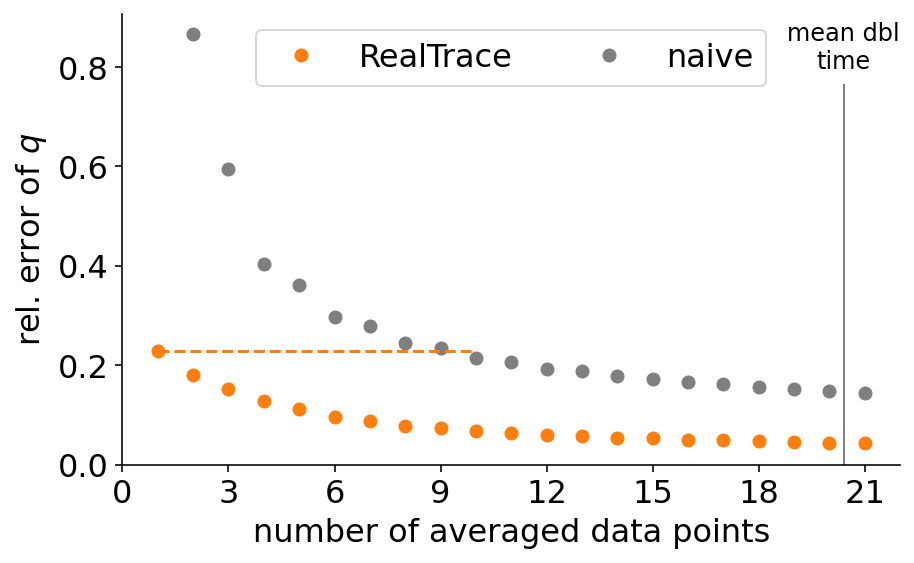

In [21]:
# compare_sliding_mean_to_prediction(cells_true, cells_prediction, cells_noise,  
compare_sliding_mean_to_prediction(cells_true, cells_prediction, cells_noise,  
                                    "q",  
                                    # title=r"relative error of $q$ $\frac{\sqrt{ \langle (q - q_{true})^2 \rangle }}{\bar q} $", 
                                    title=r"rel. error of $q$", 
                                    xlim=[None, None],
                                    ylim=[0.0, None],
                                    window_sizes=np.arange(1,22, 1), 
                                    normy=read_header(final_file)["mean_q"][1],
                                    mark_x = np.log(2)/read_header(final_file)["mean_lambda"][1],
                                    beta=read_header(final_file)["beta"][1],
                                    plot_file="../../figures_for_method_paper/plots_main/synthetic_data/naive_Realtrace_comparison_q.pdf")


### Supplement prediction

1 2 3 4 5 6 7 8 9 10 11 12 13 14 15 16 17 18 19 20 21 [ 1.  2.  3.  4.  5.  6.  7.  8.  9. 10. 11. 12. 13. 14. 15. 16. 17. 18.
 19. 20. 21.] [0.2275461  0.17989416 0.15248023 0.1272349  0.11191264 0.09618324
 0.08765184 0.07786544 0.0730377  0.06700546 0.06392327 0.05983108
 0.05750561 0.05443403 0.05252353 0.05015971 0.04852787 0.04668261
 0.0452943  0.04378827 0.0424549 ]
[ 2.  3.  4.  5.  6.  7.  8.  9. 10. 11. 12. 13. 14. 15. 16. 17. 18. 19.
 20. 21.] [0.86574478 0.59453093 0.4039072  0.36202609 0.29614194 0.2786791
 0.24466464 0.23557067 0.21353311 0.20683754 0.19255497 0.18737442
 0.17728054 0.17307024 0.16535662 0.16160624 0.15598786 0.15213151
 0.14782899 0.14399036]
[4.81252299 3.89906899 3.1745002  3.23489899 3.07893514 3.17938679
 3.14214678 3.2253296  3.1868016  3.23571561 3.2183101  3.25836763
 3.25679634 3.29509885 3.29660238 3.3301735  3.3414557  3.358734
 3.37599554 3.39160775]


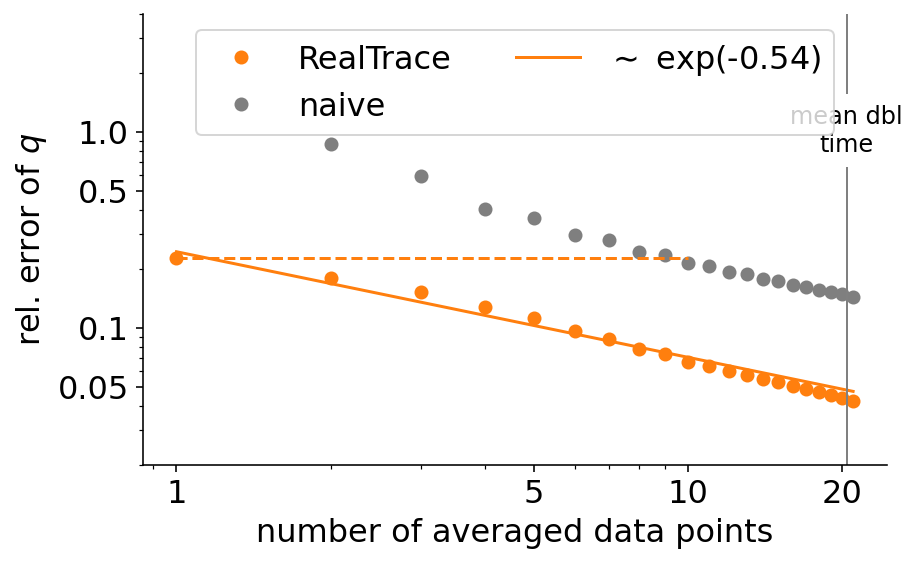

In [33]:
# compare_sliding_mean_to_prediction(cells_true, cells_prediction, cells_noise,  
compare_sliding_mean_to_prediction(cells_true, cells_prediction, cells_noise,  
                                    "q",  
                                    # title=r"relative error of $q$ $\frac{\sqrt{ \langle (q - q_{true})^2 \rangle }}{\bar q} $", 
                                    title=r"rel. error of $q$", 
                                    xlim=[None, None],
                                    ylim=[0.02, 4],
                                    log=True,
                                    window_sizes=np.arange(1,22, 1), 
                                    normy=read_header(final_file)["mean_q"][1],
                                    mark_x = np.log(2)/read_header(final_file)["mean_lambda"][1],
                                    beta=read_header(final_file)["beta"][1],
                                    plot_file="../../figures_for_method_paper/supp/synthetic_data/naive_Realtrace_comparison_q_log.pdf")


1 2 3 4 5 6 7 8 9 10 11 12 13 14 15 16 17 18 19 20 21 [ 1.  2.  3.  4.  5.  6.  7.  8.  9. 10. 11. 12. 13. 14. 15. 16. 17. 18.
 19. 20. 21.] [0.20531001 0.14898451 0.11950223 0.09625967 0.0837027  0.07169051
 0.06577101 0.05890781 0.0553466  0.05116746 0.04868758 0.04575598
 0.04389206 0.04175934 0.04023813 0.03860523 0.03729499 0.03591669
 0.03478952 0.03369067 0.03275134]
[ 2.  3.  4.  5.  6.  7.  8.  9. 10. 11. 12. 13. 14. 15. 16. 17. 18. 19.
 20. 21.] [0.49792692 0.36528634 0.25037181 0.22981553 0.18838996 0.17871862
 0.15710112 0.15163885 0.13775678 0.13395453 0.12469432 0.12150498
 0.11489476 0.11217496 0.1073655  0.10505113 0.1013583  0.09887786
 0.09591525 0.09346323]
[3.34213886 3.05673231 2.60100413 2.7456165  2.62782283 2.71728588
 2.666898   2.7398041  2.69227308 2.75130779 2.72520278 2.76826829
 2.75135469 2.78777755 2.78111274 2.81676225 2.82203869 2.84217351
 2.84693831 2.853722  ]


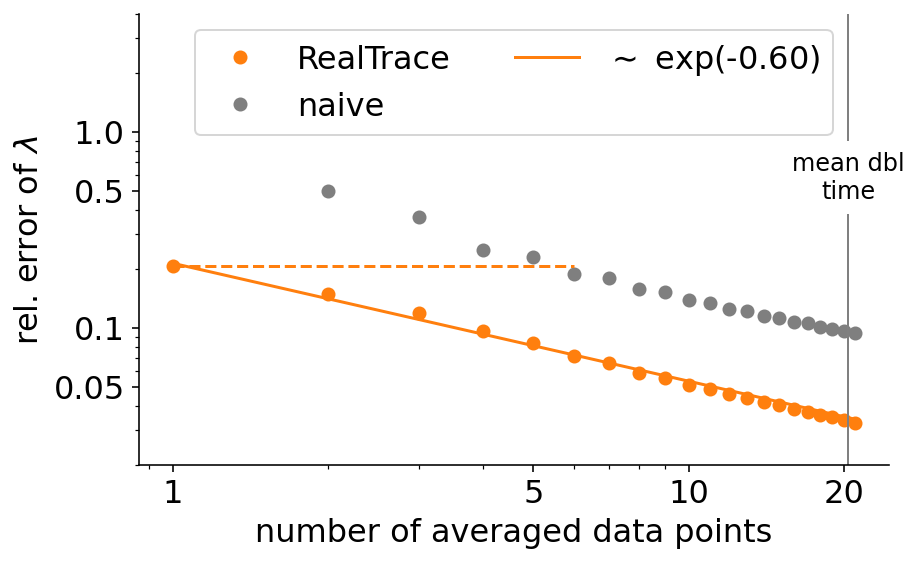

In [34]:
# compare_sliding_mean_to_prediction(cells_true, cells_prediction, cells_noise,  
compare_sliding_mean_to_prediction(cells_true, cells_prediction, cells_noise,  
                                    "lambda",  
                                    # title=r"relative error of $q$ $\frac{\sqrt{ \langle (q - q_{true})^2 \rangle }}{\bar q} $", 
                                    title=r"rel. error of $\lambda$", 
                                    xlim=[None, None],
                                    ylim=[0.02, 4],
                                    log=True,
                                    window_sizes=np.arange(1,22, 1), 
                                    normy=read_header(final_file)["mean_lambda"][1],
                                    mark_x = np.log(2)/read_header(final_file)["mean_lambda"][1],
                                    beta=read_header(final_file)["beta"][1],
                                    plot_file="../../figures_for_method_paper/supp/synthetic_data/naive_Realtrace_comparison_lambda_log.pdf")
